# Liver: ECM composition and organisation in naive and infected mouse liver (Figure 3)

This notebook reproduces Figure 3 of the paper, panels a to i, from the raw images. It groups the
extracellular matrix (ECM) of mouse liver into six ECM clusters, finds the cluster that is enriched in
*Schistosoma mansoni* infection, and tests whether the clusters and their arrangement predict infection in
mice that the classifier has not seen.

- **Data:** 24 imaging mass cytometry regions of interest (ROIs) from eight mice: naive or infected, *Sox9*
  knockout (KO) or wild type (WT). Each ROI has six ECM markers. The dataset is downloaded on first use.
- **Analysis:** ECM patches, CNN patch features, six ECM clusters, then a patch graph. The clusters are
  described (composition, marker profiles, co-occurrence, connected regions) and used to predict infection
  with a graph neural network (GNN), which is explained with integrated gradients.
- **Run time:** about 6 minutes on one CUDA GPU, including Google Colab's free T4 GPU. Without a GPU the
  notebook runs on the CPU; this has not been timed and will be much slower, because the CNN training takes
  most of the time.

Every model is trained from scratch with the paper's final settings and one training seed (seed 0). No stored
labels or weights are read, and no settings are searched. The clusters are given the paper's numbers
(section 5), so every panel can be read next to Figure 3. Each panel is followed by a comparison with the
paper's values, joined on explicit keys (ROI, mouse, cluster). The last section puts the paper's values and
this run's in one table.

How the notebook is organised:

| Section | Content |
|---|---|
| 1 to 3 | Load the images, normalise them, cut them into patches and remove the background |
| 4 to 6 | Train the patch encoder, group the patches into six ECM clusters numbered as in the paper, collect one table of patches |
| 7 to 9 | Composition and the infection-associated cluster (panel a), marker profiles (panel b) |
| 10 to 13 | Patch graphs, co-occurrence of clusters (panel c), images and cluster maps (panels d and e) |
| 14 and 15 | Prediction of infection in held-out mice (panel g) and the patches that drive it (panels f and h) |
| 16 | Connected regions of the infection-associated cluster (panel i) |
| 17 | The paper's results beside the results of this notebook |

The Mantpy functions used:

| Step | Mantpy function |
|---|---|
| Dataset | `mt.datasets.schistosoma_ecm` |
| Normalisation | `mt.pp.ImageNormalizer` |
| ECM patches | `mt.pp.ecm_patches_from_images`, `mt.pp.remove_background_patches` |
| Patch features | `mt.pp.ecm_patch_tiles`, `mt.nn.PatchEncoder` |
| ECM clusters | `mt.pp.cluster_ecm_patches`, `mt.pp.renumber_ecm_clusters`, `mt.tl.ecm_patch_table` |
| Composition | `mt.tl.compute_cluster_composition`, `mt.tl.top_enriched_cluster` |
| Patch graph | `mt.gr.build_ecm_graphs` |
| Co-occurrence | `mt.tl.cluster_cooccurrence` |
| Classifier | `mt.nn.build_ohe_cluster_graphs`, `mt.nn.NodeClassifier` |
| Explanation | `NodeClassifier.attribution_table`, `mt.tl.cluster_membership_correlation` |
| Connected regions | `mt.tl.component_summary` |
| Plots | `mt.pl.plot_mean_composition`, `mt.pl.ecm_centroid_heatmap`, `mt.pl.plot_delta_masked`, `mt.pl.plot_marker_otsu_composite`, `mt.pl.patch_map` |

Requires `mantpy[patch,gnn]` 1.3.0 or newer and the packages in `liver_requirements.txt`. Keep
`liver_helpers.py` beside this notebook. The helper file holds what is specific to reproducing the paper:
reading the paper's values, matching the clusters of this run to the paper's, the comparison tables, and the
parts of the panels that Mantpy does not draw. Each of its functions takes everything it uses as an argument.

In [1]:
# Google Colab only: fetch this repository and install the packages. Skipped on your own computer.
# After installing, the runtime restarts so that the installed versions are the ones in use. Colab reports
# this as a crashed session, which is expected: choose Runtime > Run all again.
import os, subprocess, sys, time

REVISION = "main"   # the repository revision this notebook was run from

if "google.colab" in sys.modules:
    repository = "/content/mantpy_reproducibility"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "https://github.com/moeghaf/mantpy_reproducibility", repository], check=True)
    subprocess.run(["git", "-C", repository, "checkout", "--quiet", REVISION], check=True)
    os.chdir(f"{repository}/notebooks")
    installed = "/content/liver_packages_installed"
    if not os.path.exists(installed):
        pip = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "liver_requirements.txt"],
                             capture_output=True, text=True)
        if pip.returncode != 0:
            raise RuntimeError(pip.stderr[-3000:])
        open(installed, "w").close()
        print("Packages installed. The runtime restarts now: choose Runtime > Run all again.", flush=True)
        time.sleep(2)   # gives the line above time to reach the page
        os.kill(os.getpid(), 9)

In [2]:
import logging, time, warnings

# Known messages that would repeat for every model fit are hidden here, each by its text.
# Every other warning is shown.
for message in (
    r"The '\w+' does not have many workers",               # the patches are already in memory
    r"`isinstance\(treespec, LeafSpec\)` is deprecated",   # raised inside PyTorch Lightning
    "IProgress not found",                                 # only concerns progress bars
):
    warnings.filterwarnings("ignore", message=message)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
import torch
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)   # hides "triton not found" (not used here)
import pytorch_lightning   # imported here so that its log level can be set below
import mantpy as mt
import liver_helpers as lh

# PyTorch Lightning prints several information lines for every fit. Its warnings and errors are still shown.
for name in ("pytorch_lightning", "lightning_fabric"):
    logging.getLogger(name).setLevel(logging.WARNING)

if not hasattr(mt.pp, "renumber_ecm_clusters"):
    raise RuntimeError("This notebook needs Mantpy 1.3.0 or newer (pip install -U 'mantpy[patch,gnn]').")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
STARTED = time.perf_counter()
# Full float32 precision on the GPU, as in the paper's runs.
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False
print("Mantpy", mt.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

Mantpy 1.3.0 | device: NVIDIA GeForce RTX 4070 SUPER


The settings of the analysis, the colours of the figure and the paper's values. `lh.read_paper_values` reads
the paper's source data (`source_data/fig3.xlsx`) into one table per quantity, each with explicit keys.

In [3]:
SEED = 0
CNN_EPOCHS = 200   # contrastive training of the patch encoder
GNN_EPOCHS = 120   # training of each GraphSAGE classifier
K = 6              # number of ECM clusters
PATCH = 10         # patch side, pixels (1 pixel = 1 µm)
GRID = 1000 // PATCH   # patches per image side (every ROI is 1,000 x 1,000 pixels)

GROUPS = ["Naive KO", "Naive WT", "Infected KO", "Infected WT"]
SHOWN_ROIS = {"Naive KO": "roi_017", "Naive WT": "roi_021", "Infected KO": "roi_004", "Infected WT": "roi_009"}

PALETTE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]   # ECM 0 to ECM 5
MARKER_COLOURS = {"Fibronectin": "#e41a1c", "Pan-laminin": "#ffd400", "CollagenIV": "#ff33cc",
                  "VersicanV0V1": "#a040ff", "CollagenI": "#1f77ff", "HeparanSulfate": "#2ecc40"}
MARKER_LABELS = {"Fibronectin": "Fibronectin", "Pan-laminin": "Pan-laminin", "CollagenIV": "Collagen IV",
                 "VersicanV0V1": "Versican V0/V1", "CollagenI": "Collagen I", "HeparanSulfate": "Heparan sulfate"}
IMPORTANCE_CMAP = LinearSegmentedColormap.from_list("importance", ["#F2EFF7", "#9E9AC8", "#54278F", "#2A0A4A"])
DEGREE_CMAP = plt.get_cmap("coolwarm")
MAX_DEGREE = 45    # upper end of the node-degree colour scale

PAPER = lh.read_paper_values("../source_data/fig3.xlsx")   # cluster numbers as in the paper

## 1. Load the liver cohort

`mt.datasets.schistosoma_ecm` downloads the public dataset on first use and returns the raw images (six ECM
markers per ROI), the marker panel and one metadata row per ROI. Naive mice have two ROIs each and infected
mice four.

In [4]:
liver = mt.datasets.schistosoma_ecm(progressbar=False, verbose=False)
images = liver.images
MARKERS = list(liver.ecm_names)
meta = liver.sample_meta.drop(columns="sample_id").rename(columns={"mouse_id": "mouse"}).astype(str)
meta.index.name = "roi"
meta["group"] = meta["group"].str.replace("_", " ")

assert MARKERS == list(MARKER_COLOURS), "the marker panel differs from the paper's"
assert list(images) == sorted(images) == list(meta.index), "images and metadata must list the same ROIs"
assert all(image.shape == (len(MARKERS), 1000, 1000) for image in images.values())
assert [group.replace("_", " ") for group in liver.group_order] == GROUPS

print(f"{len(images)} ROIs, {meta.mouse.nunique()} mice | markers: " + ", ".join(MARKERS))
meta.groupby("mouse").agg(group=("group", "first"), ROIs=("group", "size"))

24 ROIs, 8 mice | markers: Fibronectin, Pan-laminin, CollagenIV, VersicanV0V1, CollagenI, HeparanSulfate


,group,ROIs
mouse,,
mouse_01,Infected KO,4
mouse_02,Infected KO,4
mouse_03,Infected WT,4
mouse_04,Infected WT,4
mouse_05,Naive KO,2
mouse_06,Naive KO,2
mouse_07,Naive WT,2
mouse_08,Naive WT,2


## 2. Normalise the images and divide them into patches

`mt.pp.ImageNormalizer` with `method="pooled_arcsinh_percentile"` applies arcsinh (cofactor 1), divides each
marker by its 99.5th percentile pooled over all 24 ROIs, and clips to [0, 1].

`mt.pp.ecm_patches_from_images` then divides every image into non-overlapping 10 x 10-pixel patches and stores,
for each patch, the mean and standard deviation of each marker (12 numbers) in `uns["ecm_patches"]`. All
10,000 patches of an ROI are kept at this stage (`background_quantile=0`, `ecm_K=None`); background is removed
in the next step.

In [5]:
normaliser = mt.pp.ImageNormalizer(
    method="pooled_arcsinh_percentile", cofactor=1.0, percentile=99.5, channel_names=MARKERS,
).fit(images)
normalised = normaliser.transform_cohort(images)

cohort = mt.pp.ecm_patches_from_images(
    normalised, liver.panel, normalize="none", patch_size=PATCH, features=["mean", "std"],
    ecm_K=None, background_quantile=0.0,
)
print(f"{sum(len(adata.uns['ecm_patches']) for adata in cohort.values()):,} patches in {len(cohort)} ROIs")

240,000 patches in 24 ROIs


**Comparison with the paper.** The 99.5th percentile of each marker after arcsinh (the normalisation bound).

In [6]:
bounds = pd.Series(np.asarray(normaliser.bounds_, dtype=float), index=pd.Index(MARKERS, name="marker"))
lh.side_by_side(bounds, PAPER["bounds"]).round(6)

,this run,paper
marker,,
Fibronectin,2.776472,2.776472
Pan-laminin,2.491780,2.491780
CollagenIV,2.312438,2.312438
VersicanV0V1,2.312438,2.312438
CollagenI,3.179785,3.179785
HeparanSulfate,2.491780,2.491780


## 3. Remove background patches

`mt.pp.cluster_ecm_patches` with `n_clusters=2` standardises the 12 patch features over the cohort and splits
the patches into two groups by K-means. `mt.pp.remove_background_patches` marks the dimmer group as background
(label -1). The remaining patches are the ECM signal patches used from here on.

The number of signal patches is printed from the run. It can differ from the paper's by a few hundred patches
(less than 1%), because this K-means split changes in a few patches with the versions of the numerical
libraries and the number of CPU threads. The command-line pipeline of this repository starts from the paper's
deposited signal patches when it reproduces the paper's selection. This notebook uses the patches of its own
run.

In [7]:
two_groups = mt.pp.cluster_ecm_patches(cohort, n_clusters=2, random_state=0, n_init=10)
removed = mt.pp.remove_background_patches(cohort, two_groups)

n_signal = sum(int((adata.uns["ecm_patches"]["ecm_cluster"] >= 0).sum()) for adata in cohort.values())
print(f"ECM signal patches: {n_signal:,} (paper: {int(PAPER['cluster_sizes'].sum()):,}) | "
      f"background patches: {removed.background_patches:,}")

ECM signal patches: 107,732 (paper: 107,740) | background patches: 132,268


## 4. Train the patch encoder

The encoder looks at pixels, not at patch summaries: its input is the six-channel 10 x 10-pixel block of each
signal patch. `mt.pp.ecm_patch_tiles` cuts these blocks from the normalised images, in the same row order as
the patch tables.

`mt.nn.PatchEncoder` trains a small CNN without labels (contrastive learning): two randomly altered copies of
the same patch (flips, transposition, intensity changes, noise) should receive similar features, and different
patches different ones (NT-Xent loss, temperature 0.1). The options below select the paper's final encoder:

- two stride-2 convolution blocks with 32 and 64 channels, batch normalisation and GELU;
- 2 x 2 max pooling, then a linear layer to 96 features;
- 200 epochs, batch size 1,024, AdamW with learning rate 3e-4 and weight decay 1e-4.

`encoder.transform` returns the 96 features of every patch.

On a GPU, PyTorch prints one warning in this step: max pooling has no deterministic GPU implementation, so
repeated GPU runs with the same seed are not guaranteed to give identical numbers.

In [8]:
tiles = mt.pp.ecm_patch_tiles(cohort, normalised, subset="signal")   # (patches, 6 markers, 10, 10)

started = time.perf_counter()
encoder = mt.nn.PatchEncoder(
    latent_dim=96, temperature=0.1, conv_blocks=2, conv_width=32, conv_activation="gelu",
    pool_size=2, pool_type="max",
)
encoder.fit(
    tiles, max_epochs=CNN_EPOCHS, batch_size=1024, lr=3e-4, weight_decay=1e-4,
    random_state=SEED, accelerator=DEVICE, num_workers=0, drop_last=False, exhaust_sampler=True,
    enable_progress_bar=False, enable_model_summary=False,
)
embedding = encoder.transform(tiles, batch_size=4096, standardize=False)

loss = encoder.history["train_loss"]
print(f"{len(tiles):,} patches, {embedding.shape[1]} features each | {len(loss)} epochs in "
      f"{time.perf_counter() - started:.0f} s | contrastive loss {loss[0]:.3f} -> {loss[-1]:.3f}")

C:\dev\clean-130-gpu\Lib\site-packages\torch\autograd\graph.py:979: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


107,732 patches, 96 features each | 200 epochs in 293 s | contrastive loss 5.074 -> 0.281


## 5. Group the patches into six ECM clusters

`mt.pp.cluster_ecm_patches` with `embedding=` standardises the 96 features and runs K-means with K = 6 on the
signal patches. `order_by="size"` numbers the clusters 0 to 5 from the largest to the smallest. The labels
are written to the column `ecm_cluster` of each patch table; background patches keep the label -1.

In [9]:
clusters = mt.pp.cluster_ecm_patches(
    cohort, n_clusters=K, subset="signal", embedding=embedding, random_state=0, n_init=10, order_by="size",
)
print("Patches per cluster, by size:", ", ".join(f"{int(size):,}" for size in np.asarray(clusters.component_sizes)))

Patches per cluster, by size: 32,894, 23,731, 20,275, 11,621, 11,179, 8,032


**The paper's cluster numbers.** Because the numbers follow cluster size, two clusters of similar size can swap
numbers between runs. The clusters of this run are therefore given the paper's numbers, so that every panel
can be read next to Figure 3:

- `mt.pl.ecm_centroid_table` gives the marker profile of each cluster: the mean normalised intensity of each
  marker and its z-score across the six clusters.
- `lh.match_clusters` pairs every cluster of this run with one cluster of the paper, so that the summed
  correlation between the paired profiles is as large as possible. Two clusters of this run can never be
  paired with the same paper cluster.
- `mt.pp.renumber_ecm_clusters` writes the paired numbers to the patch tables. Every patch stays in its
  cluster; only the numbers change.

From here on, ECM 0 to ECM 5 are the paper's cluster numbers. The table shows the pairing: the number each
cluster had by size, its size in this run and in the paper, the correlation of its profile with the paired
paper cluster, and how close the second-best paper cluster was.

In [10]:
centroids = mt.pl.ecm_centroid_table(cohort, ecm_names=MARKERS, K_ecm=K)
by_size = centroids.pivot(index="cluster", columns="marker", values="z_score")[MARKERS]   # numbered by size

matching = lh.match_clusters(by_size, PAPER["profiles"][MARKERS])
sizes = mt.pp.renumber_ecm_clusters(cohort, matching["paper cluster"])
profiles = by_size.rename(index=matching["paper cluster"]).sort_index()   # the same profiles, the paper's numbers

pairing = matching.rename_axis("number by size").reset_index().set_index("paper cluster").sort_index()
pd.DataFrame({
    "number by size": pairing["number by size"],
    "patches, this run": pd.Series(sizes),
    "patches, paper": PAPER["cluster_sizes"],
    "profile correlation": pairing["profile correlation"].round(3),
    "highest correlation with another paper cluster":
        pairing["highest correlation with another paper cluster"].round(3),
}).rename_axis("cluster").rename(index="ECM {}".format)

,number by size,"patches, this run","patches, paper",profile correlation,highest correlation with another paper cluster
cluster,,,,,
ECM 0,0,32894,32469,0.999,0.036
ECM 1,1,23731,23232,0.999,0.187
ECM 2,2,20275,21786,0.992,0.162
ECM 3,3,11621,11982,0.999,0.079
ECM 4,4,11179,10036,0.989,0.284
ECM 5,5,8032,8235,1.000,0.171


## 6. One table of all ECM patches

`mt.tl.ecm_patch_table` stacks the patch tables of the 24 ROIs into one long table: one row per signal patch,
with its position, its cluster, and the name of its node in the patch graph (`node_id`), which later steps
use to attach results to patches.

In [11]:
patches = (
    mt.tl.ecm_patch_table(cohort, sample_meta=meta[["mouse", "group"]], drop_background=True)
    .rename(columns={"sample_id": "roi", "ecm_cluster": "cluster"})
    .astype({"x": int, "y": int, "cluster": int})
)
assert len(patches) == n_signal and not patches.duplicated(["roi", "node_id"]).any()
print(f"{len(patches):,} labelled ECM patches")
patches.head(3)

107,732 labelled ECM patches


,roi,node_id,x,y,cluster,mouse,group
0,roi_001,ecm_0,5,5,1,mouse_01,Infected KO
1,roi_001,ecm_1,15,5,1,mouse_01,Infected KO
2,roi_001,ecm_7,75,5,1,mouse_01,Infected KO


## 7. Composition per mouse and the infection-associated cluster

`mt.tl.compute_cluster_composition` counts the patches of each cluster. With `unit_col="mouse"` and
`unit_aggregation="pool_counts"` the patches of a mouse are pooled over its ROIs before fractions are taken,
and group values are the mean of the two mice.

The infection-associated cluster is then chosen by the paper's rule, from these fractions alone
(`composition.contrast`, then `mt.tl.top_enriched_cluster`): among the clusters that make up at least 1% of
the ECM patches in every infected mouse, take the one with the largest ratio of mean infected to mean naive
fraction (pseudocount 0.001). In the paper this is ECM 5. The cluster number used in the rest of the notebook
comes from this rule.

In [12]:
composition = mt.tl.compute_cluster_composition(
    cohort, sample_meta=meta, group_col="group", group_order=GROUPS, cluster_col="ecm_cluster",
    label_source="patches", drop_background=True, categories=range(K),
    unit_col="mouse", unit_aggregation="pool_counts", return_details=True,
)
per_mouse = composition.per_unit               # fraction of each cluster in each mouse
mouse_group = composition.unit_meta["group"]   # the group of each mouse

contrast = composition.contrast(case=["Infected KO", "Infected WT"], control=["Naive KO", "Naive WT"],
                                pseudocount=1e-3, min_fraction=0.01)
INFECTION_CLUSTER = int(mt.tl.top_enriched_cluster(contrast, log2_col="log2_ratio", sig_col="present"))

print(f"Infection-associated cluster: ECM {INFECTION_CLUSTER} (paper: ECM {PAPER['infection_cluster']})")
contrast.set_index("cluster").rename(index="ECM {}".format).round(3)

Infection-associated cluster: ECM 5 (paper: ECM 5)


,mean_case,mean_control,difference,log2_ratio,min_case_fraction,present,n_case_units,n_control_units
cluster,,,,,,,,
ECM 0,0.289,0.302,-0.013,-0.062,0.169,True,4,4
ECM 1,0.255,0.108,0.147,1.230,0.133,True,4,4
ECM 2,0.130,0.406,-0.276,-1.634,0.035,True,4,4
ECM 3,0.110,0.124,-0.014,-0.169,0.072,True,4,4
ECM 4,0.121,0.060,0.062,1.012,0.075,True,4,4
ECM 5,0.094,0.000,0.094,6.491,0.031,True,4,4


## 8. ECM composition (Figure 3a)

Mean fraction of ECM patches in each cluster, per group, drawn with `mt.pl.plot_mean_composition`. The
percentage above the infected bars is the share of the infection-associated cluster.

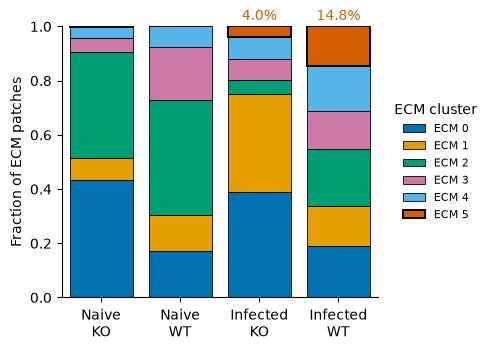

In [13]:
group_fractions = composition.per_group_mean

fig, ax = plt.subplots(figsize=(4.8, 3.4), layout="constrained")
mt.pl.plot_mean_composition(
    ax, group_fractions, list(range(K)), palette=PALETTE, group_order=GROUPS, target_cluster=INFECTION_CLUSTER,
    title=None, group_labels=[group.replace(" ", "\n") for group in GROUPS],
)
for position, group in enumerate(GROUPS):
    if group.startswith("Infected"):
        ax.text(position, 1.012, f"{100 * group_fractions.loc[group, INFECTION_CLUSTER]:.1f}%",
                ha="center", va="bottom", color=PALETTE[INFECTION_CLUSTER])
ax.set_ylabel("Fraction of ECM patches")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Comparison with the paper.** The fraction of each cluster per group (mean of two mice), then the share of the
infection-associated cluster in each infected mouse.

In [14]:
display(lh.side_by_side(group_fractions, PAPER["group_fractions"]).rename(columns="ECM {}".format).round(3))

infected_mice = mouse_group.index[mouse_group.str.startswith("Infected")]
(lh.side_by_side(per_mouse.loc[infected_mice, INFECTION_CLUSTER],
                 PAPER["mouse_fractions"].loc[infected_mice, PAPER["infection_cluster"]])
 .assign(group=mouse_group).round(3))

cluster               ECM 0  ECM 1  ECM 2  ECM 3  ECM 4  ECM 5
                                                              
Naive KO    this run  0.432  0.084  0.388  0.053  0.042  0.000
            paper     0.432  0.068  0.406  0.055  0.038  0.000
Naive WT    this run  0.172  0.133  0.423  0.195  0.077  0.000
            paper     0.189  0.109  0.442  0.192  0.067  0.000
Infected KO this run  0.389  0.363  0.049  0.079  0.079  0.040
            paper     0.377  0.366  0.064  0.084  0.068  0.040
Infected WT this run  0.189  0.148  0.211  0.141  0.163  0.148
            paper     0.187  0.144  0.220  0.146  0.150  0.152

,this run,paper,group
mouse,,,
mouse_01,0.031,0.033,Infected KO
mouse_02,0.049,0.048,Infected KO
mouse_03,0.089,0.095,Infected WT
mouse_04,0.206,0.210,Infected WT


## 9. Marker profiles of the clusters (Figure 3b)

`mt.pl.ecm_centroid_heatmap` draws the z-scores of the marker profiles computed in section 5: the mean
normalised intensity of each marker in each cluster, as a z-score across the six clusters.

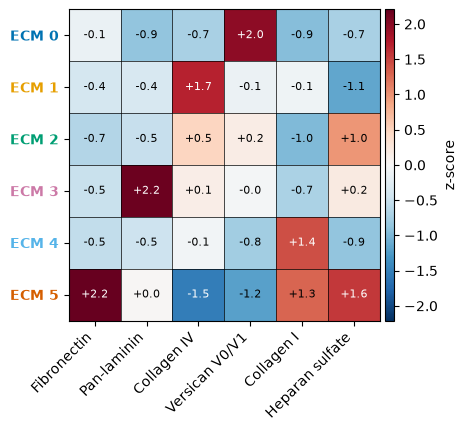

In [15]:
fig, ax = plt.subplots(figsize=(5.4, 4.2), layout="constrained")
mt.pl.ecm_centroid_heatmap(cohort, ecm_names=MARKERS, K_ecm=K, cluster_colors=PALETTE, colorbar_label="z-score",
                           ax=ax, show=False)
ax.set_xticklabels([MARKER_LABELS[marker] for marker in MARKERS])
plt.show()

**Comparison with the paper.** Marker z-scores of each cluster, in this run and in the paper.

In [16]:
lh.side_by_side(profiles, PAPER["profiles"][MARKERS]).rename(index="ECM {}".format, level="cluster").round(2)

marker            Fibronectin  Pan-laminin  CollagenIV  VersicanV0V1  \
cluster                                                                
ECM 0   this run        -0.14        -0.86       -0.72          1.98   
        paper           -0.16        -0.86       -0.79          2.03   
ECM 1   this run        -0.39        -0.36        1.70         -0.14   
        paper           -0.37        -0.30        1.67         -0.12   
ECM 2   this run        -0.65        -0.51        0.48          0.17   
        paper           -0.63        -0.47        0.64          0.02   
ECM 3   this run        -0.49         2.16        0.14         -0.04   
        paper           -0.48         2.14        0.22         -0.08   
ECM 4   this run        -0.54        -0.46       -0.07         -0.77   
        paper           -0.57        -0.59       -0.32         -0.68   
ECM 5   this run         2.21         0.03       -1.53         -1.20   
        paper            2.21         0.08       -1.42         -1.18   

marker            CollagenI  HeparanSulfate  
cluster                                      
ECM 0   this run      -0.94           -0.71  
        paper         -0.96           -0.65  
ECM 1   this run      -0.09           -1.14  
        paper         -0.10           -1.17  
ECM 2   this run      -0.98            0.98  
        paper         -0.94            1.01  
ECM 3   this run      -0.69            0.20  
        paper         -0.71            0.15  
ECM 4   this run       1.42           -0.88  
        paper          1.42           -0.89  
ECM 5   this run       1.29            1.55  
        paper          1.29            1.54

## 10. Build the patch graphs

`mt.gr.build_ecm_graphs` with `edge_method="delaunay"` joins the centres of **all** patches of an ROI (signal
and background) by Delaunay triangulation and stores the graph in `uns["ecm_graph"]`. Each node carries its
cluster label, so the graphs are built after the labels were written. Later steps use only the edges between
two ECM signal patches.

In [17]:
graph_summary = mt.gr.build_ecm_graphs(cohort, edge_method="delaunay", edge_weight="uniform")
print(f"{graph_summary.n_nodes:,} nodes and {graph_summary.n_edges:,} edges in {len(graph_summary.samples)} ROI graphs")

240,000 nodes and 710,424 edges in 24 ROI graphs


## 11. Co-occurrence of clusters, infected knockout minus wild type (Figure 3c)

`mt.tl.cluster_cooccurrence` counts, for every pair of clusters, the graph edges that join them (observed) and
compares the count with the number expected from cluster abundance alone: log2(observed / expected). With
`unit_col="mouse"` the counts of a mouse are pooled over its ROIs. Positive values mean that the two clusters
are neighbours more often than expected.

With `group_col="group"` the result also knows the group of each mouse. `cooccurrence.contrast` then gives the
mean of the two infected knockout mice minus the mean of the two infected wild-type mice.

In [18]:
cooccurrence = mt.tl.cluster_cooccurrence(
    cohort, n_clusters=K, sample_meta=meta, unit_col="mouse", unit_aggregation="pool_counts",
    group_col="group", return_details=True, missing="nan", eps=1e-9,
)
ko_minus_wt = cooccurrence.contrast(case="Infected KO", control="Infected WT")

mice_of = cooccurrence.unit_meta.groupby("group").groups
print("Infected KO:", ", ".join(mice_of["Infected KO"]), "| Infected WT:", ", ".join(mice_of["Infected WT"]))

Infected KO: mouse_01, mouse_02 | Infected WT: mouse_03, mouse_04


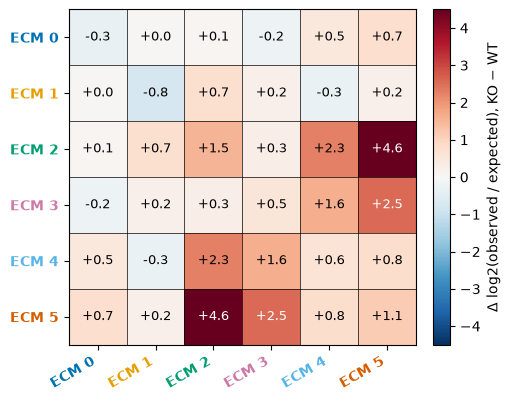

In [19]:
fig, ax = plt.subplots(figsize=(5.0, 3.9), layout="constrained")
image = mt.pl.plot_delta_masked(ax, ko_minus_wt, palette=PALETTE, K=K, mask_nonsignificant=False,
                                show_values=True, vlim=4.5)
fig.colorbar(image, ax=ax, label="Δ log2(observed / expected), KO − WT")
plt.show()

**Comparison with the paper.** The correlation over all cluster pairs where both values are defined, then the
pairs that include the infection-associated cluster.

In [20]:
r_pairs, n_pairs = lh.joint_correlation(lh.unordered_pairs(ko_minus_wt), lh.unordered_pairs(PAPER["ko_minus_wt"]))
print(f"Pearson r between this run and the paper over {n_pairs} cluster pairs: {r_pairs:.2f}")

(lh.side_by_side(ko_minus_wt[INFECTION_CLUSTER], PAPER["ko_minus_wt"][PAPER["infection_cluster"]])
 .rename(index="ECM {}".format).rename_axis(f"ECM {INFECTION_CLUSTER} with").round(2))

Pearson r between this run and the paper over 21 cluster pairs: 0.99


,this run,paper
ECM 5 with,,
ECM 0,0.74,0.79
ECM 1,0.24,0.07
ECM 2,4.57,4.21
ECM 3,2.54,2.29
ECM 4,0.79,0.88
ECM 5,1.13,1.20


## 12. Six-marker images of four ROIs (Figure 3d)

One representative ROI per group (the ROIs shown in the paper). `mt.pl.plot_marker_otsu_composite` shows each
marker where it exceeds its Otsu threshold in that image and adds the marker colours. The display scale is set
per image; the paper's panel used the pooled normalisation bounds and fixed display thresholds, so the
brightness of single markers can differ a little from the published panel. No analysis step uses these
images.

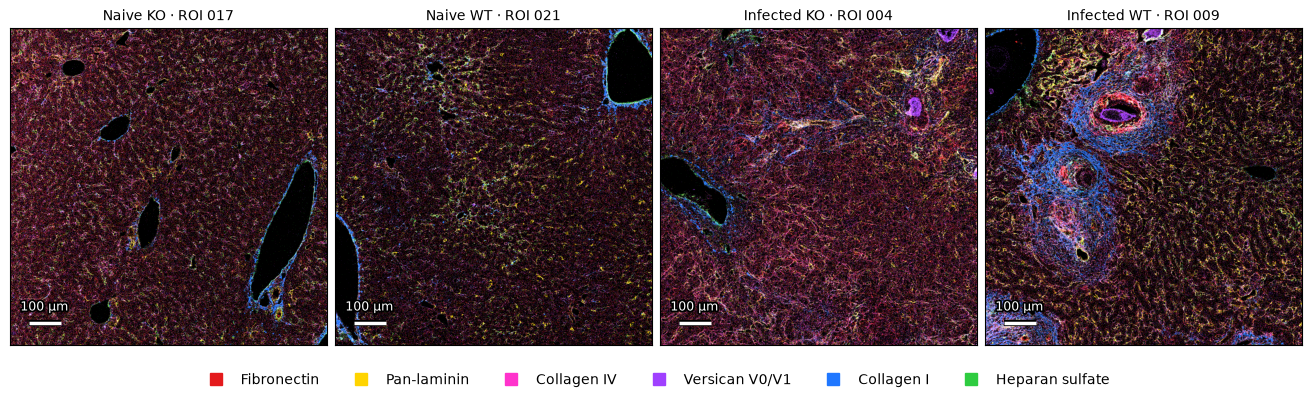

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.9), layout="constrained")
for ax, (group, roi) in zip(axes, SHOWN_ROIS.items()):
    mt.pl.plot_marker_otsu_composite(ax, cohort[roi], MARKERS, colors=[MARKER_COLOURS[marker] for marker in MARKERS],
                                     blend="add", alpha=1.0)
    lh.scale_bar(ax, 100, "100 µm", color="white")
    ax.set_title(f"{group} · {roi.replace('roi_', 'ROI ')}", fontsize=10)
fig.legend(handles=[Line2D([], [], linestyle="", marker="s", markersize=8, color=MARKER_COLOURS[marker],
                           label=MARKER_LABELS[marker]) for marker in MARKERS],
           loc="outside lower center", ncol=len(MARKERS), frameon=False)
plt.show()

## 13. Cluster maps of the same ROIs (Figure 3e)

`mt.pl.patch_map` colours each 10 x 10-pixel patch by its ECM cluster; white patches have no ECM signal.

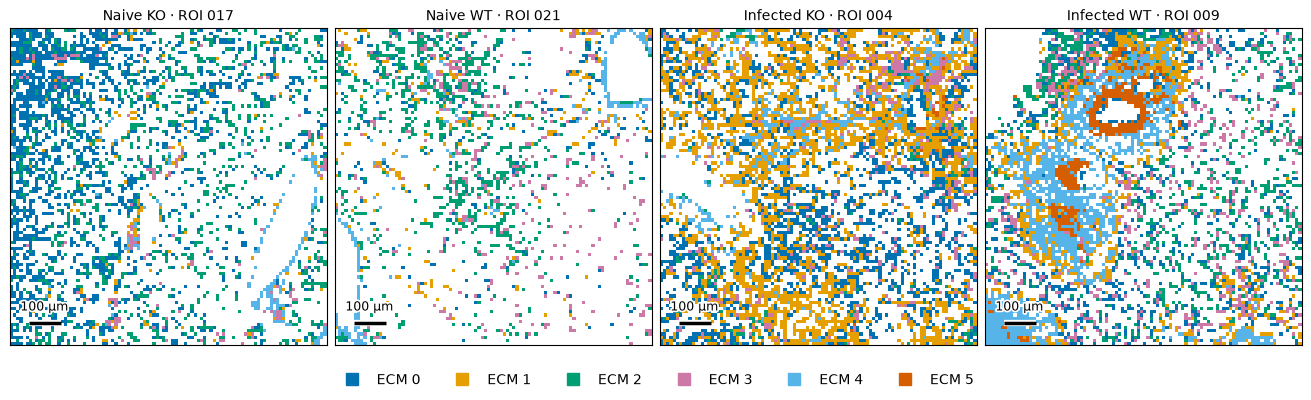

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.9), layout="constrained")
for ax, (group, roi) in zip(axes, SHOWN_ROIS.items()):
    mt.pl.patch_map(patches[patches.roi == roi], "cluster", patch_size=PATCH, shape=(GRID, GRID),
                    palette=dict(enumerate(PALETTE)), ax=ax)
    lh.scale_bar(ax, 100 / PATCH, "100 µm")
    ax.set_title(f"{group} · {roi.replace('roi_', 'ROI ')}", fontsize=10)
fig.legend(handles=[Line2D([], [], linestyle="", marker="s", markersize=8, color=PALETTE[k], label=f"ECM {k}")
                    for k in range(K)],
           loc="outside lower center", ncol=K, frameon=False)
plt.show()

**Comparison with the paper.** Number of ECM patches, and of patches of the infection-associated cluster, in
the four ROIs shown.

In [23]:
shown_rois = list(SHOWN_ROIS.values())
pd.concat({"this run": lh.patch_counts(patches, shown_rois, INFECTION_CLUSTER),
           "paper": lh.patch_counts(PAPER["shown_patches"], shown_rois, PAPER["infection_cluster"])}, axis=1)

this run                                                   paper  \
        ECM patches patches of the infection-associated cluster ECM patches   
roi                                                                           
roi_017        3123                                           1        3123   
roi_021        1821                                           0        1821   
roi_004        5389                                          35        5389   
roi_009        4616                                         370        4617   

                                                     
        patches of the infection-associated cluster  
roi                                                  
roi_017                                           0  
roi_021                                           0  
roi_004                                          33  
roi_009                                         408

## 14. Predict infection in each held-out mouse (Figure 3g)

`mt.nn.build_ohe_cluster_graphs` turns each ROI into a graph for learning: the nodes are the ECM signal
patches, the only node feature is the cluster label (one-hot), and the edges are the Delaunay edges between
signal patches. Nothing else about the image is given to the classifier.

Each mouse is held out in turn: the classifier is trained on the ROIs of the other seven mice and applied to
the ROIs of the held-out mouse. The table below lists the folds.

**What is held out, and what is not.** The earlier steps were fitted once, on the whole cohort, and none of
them uses the infection labels:

| Step | Fitted on | Uses the infection labels |
|---|---|---|
| Normalisation bounds (section 2) | all 24 ROIs | no |
| Background split (section 3) | all patches of all 24 ROIs | no |
| Patch encoder (section 4) | all ECM signal patches of all 24 ROIs | no |
| ECM clusters (section 5) | all ECM signal patches of all 24 ROIs | no |
| Graph classifier and logistic regression (this section) | the ROIs of the seven other mice of each fold | yes |

A held-out mouse is therefore unseen by the classifier, but its images took part in the unsupervised steps
that produce the cluster labels. The held-out probabilities test the classifier on fixed cluster labels; they
do not test the whole chain from raw images on a new mouse. The infection-associated cluster (section 7) is
chosen with the labels of all eight mice. It is not an input of the classifiers; it is used only to describe
their explanation in panels f, h and i.

In [24]:
learning = mt.nn.build_ohe_cluster_graphs(cohort, meta, group_col="condition", group_order=["Naive", "Infected"])
mice = meta.loc[learning.roi_ids, "mouse"].to_numpy()
folds = [(np.flatnonzero(mice != mouse), np.flatnonzero(mice == mouse)) for mouse in sorted(set(mice))]
assert all(set(mice[train]).isdisjoint(mice[test]) for train, test in folds), "a mouse is on both sides of a fold"

pd.DataFrame({
    "held-out mouse": [mice[test][0] for _, test in folds],
    "group": [mouse_group[mice[test][0]] for _, test in folds],
    "ROIs held out": [len(test) for _, test in folds],
    "ROIs trained on": [len(train) for train, _ in folds],
    "mice trained on": [len(set(mice[train])) for train, _ in folds],
}).set_index("held-out mouse")

,group,ROIs held out,ROIs trained on,mice trained on
held-out mouse,,,,
mouse_01,Infected KO,4,20,7
mouse_02,Infected KO,4,20,7
mouse_03,Infected WT,4,20,7
mouse_04,Infected WT,4,20,7
mouse_05,Naive KO,2,22,7
mouse_06,Naive KO,2,22,7
mouse_07,Naive WT,2,22,7
mouse_08,Naive WT,2,22,7


`mt.nn.NodeClassifier` trains a two-layer GraphSAGE network (64 hidden units, mean aggregation, dropout 0.2;
120 epochs, Adam, learning rate 5e-3, weight decay 1e-4). `loss_reduction="roi"` averages the class-weighted
loss within each ROI, so that large ROIs do not dominate. The probability for a mouse is the mean over its
ROIs; 0.5 is the cut-off. The classifier runs on the GPU when one is available, otherwise on the CPU.

For comparison, `classifier.composition_baseline` fits a logistic regression (LR) that is given only the
cluster fractions of each ROI (composition, no graph), with the same held-out mice. Its regularisation
strength C for each fold is the value selected in the paper.

In [25]:
started = time.perf_counter()
classifier = mt.nn.NodeClassifier(learning.graphs, n_classes=2, hidden_dim=64, n_layers=2, dropout=0.2, device=DEVICE)
classifier.fit(splits=folds, groups=mice, seeds=[SEED], reset_seed_per_fit=True, loss_reduction="roi",
               epochs=GNN_EPOCHS, lr=5e-3, weight_decay=1e-4)
held_out = classifier.prediction_table(level="group").query("estimate == 'ensemble'").set_index("unit_id").sort_index()
print(f"{len(folds)} held-out mice, {GNN_EPOCHS} epochs each, in {time.perf_counter() - started:.0f} s")

# Composition-only reference on the same held-out mice; C per held-out mouse as selected in the paper.
LR_C = {"mouse_01": 1.0, "mouse_02": 1.0, "mouse_03": 10.0, "mouse_04": 10.0,
        "mouse_05": 10.0, "mouse_06": 1.0, "mouse_07": 10.0, "mouse_08": 1.0}
baseline = classifier.composition_baseline(C=LR_C, max_iter=10000).set_index("unit_id")

probabilities = pd.DataFrame({"GNN, seed 0": held_out.probability_class_1,
                              "LR": baseline.probability_class_1}).rename_axis("mouse")
infected = held_out.true_class_idx.eq(1).rename_axis("mouse")   # the true class of each mouse

8 held-out mice, 120 epochs each, in 14 s


In the plot, each symbol is one held-out mouse: circles for the graph network (GNN), diamonds for the
composition-only logistic regression (LR). Filled symbols are infected mice and open symbols naive mice. The
dashed line is the 0.5 cut-off, so a mouse is classified correctly when a filled symbol lies above the line
or an open symbol below it.

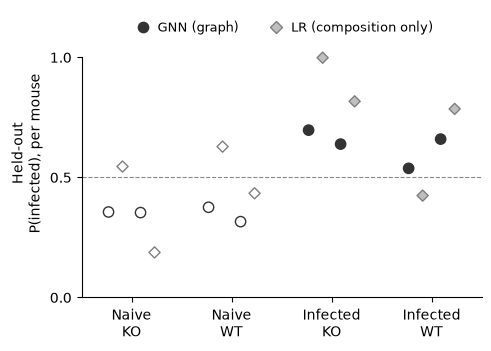

In [26]:
fig, ax = plt.subplots(figsize=(4.8, 3.4), layout="constrained")
lh.plot_held_out_probabilities(ax, probabilities["GNN, seed 0"], probabilities["LR"], group=mouse_group,
                               positive=infected, group_order=GROUPS)
ax.set_ylabel("Held-out\nP(infected), per mouse")
plt.show()

**Comparison with the paper.** The held-out probability of infection per mouse, then the summary over the eight
mice. The paper's panel shows the mean of five training seeds; its seed-0 values are the like-for-like
comparison for this run.

In [27]:
display(pd.concat({"this run": probabilities, "paper": PAPER["probabilities"].loc[probabilities.index]}, axis=1)
        .assign(group=mouse_group).round(3))

pd.concat({"this run": lh.classification_summary(probabilities, infected),
           "paper": lh.classification_summary(PAPER["probabilities"].loc[infected.index], infected)})

this run              paper                               group
         GNN, seed 0     LR GNN, seed 0 GNN, five seeds     LR             
mouse                                                                      
mouse_01       0.697  0.998       0.729           0.743  1.000  Infected KO
mouse_02       0.639  0.817       0.639           0.633  0.790  Infected KO
mouse_03       0.538  0.424       0.562           0.547  0.457  Infected WT
mouse_04       0.660  0.785       0.664           0.662  0.794  Infected WT
mouse_05       0.356  0.545       0.365           0.365  0.454     Naive KO
mouse_06       0.354  0.188       0.384           0.354  0.137     Naive KO
mouse_07       0.376  0.628       0.370           0.376  0.607     Naive WT
mouse_08       0.316  0.434       0.319           0.321  0.435     Naive WT

classified correctly (of 8)  ROC AUC
this run GNN, seed 0                                8   1.0000
         LR                                         5   0.8125
paper    GNN, seed 0                                8   1.0000
         GNN, five seeds                            8   1.0000
         LR                                         6   0.9375

## 15. Which patches drive the prediction? (Figure 3f, h)

A second set of classifiers is trained for explanation, as in the paper: same network and held-out mice, with
the loss averaged over patches (`loss_reduction="node"`). `explainer.attribution_table` then scores every patch
of a held-out ROI with integrated gradients: by how much its cluster label moves the prediction towards
"infected" (zero baseline, 50 steps). Each ROI is explained by the network that held it out.

The table also reports `max_abs_delta`, the convergence error of integrated gradients for each ROI: the gap
between the summed scores and the change of the prediction they should add up to. The largest value is printed
as a check of the 50-step approximation.

In [28]:
started = time.perf_counter()
explainer = mt.nn.NodeClassifier(learning.graphs, n_classes=2, hidden_dim=64, n_layers=2, dropout=0.2, device=DEVICE)
explainer.fit(splits=folds, groups=mice, seeds=[SEED], reset_seed_per_fit=True, loss_reduction="node",
              epochs=GNN_EPOCHS, lr=5e-3, weight_decay=1e-4)
importance = explainer.attribution_table(target_class=1, n_steps=50, internal_batch_size=1)

print(f"Explanation classifiers and integrated gradients for {importance.sample_id.nunique()} ROIs "
      f"in {time.perf_counter() - started:.0f} s")
print(f"Largest convergence error over the ROIs: {importance.max_abs_delta.max():.2g} "
      f"(median summed absolute score of an ROI: {importance.groupby('sample_id').node_importance.sum().median():.2g})")

Explanation classifiers and integrated gradients for 24 ROIs in 18 s
Largest convergence error over the ROIs: 0.0076 (median summed absolute score of an ROI: 2.6)


The scores are attached to the patch table on the keys (`roi`, `node_id`). The join is checked: every ECM patch
must receive exactly one finite score, because a missing score would change the percentile used for the colour
scale. For the maps, the absolute scores are divided by their 99th percentile over all infected ROIs.

In [29]:
scores = importance.rename(columns={"sample_id": "roi", "node_importance": "abs_ig"})[["roi", "node_id", "abs_ig"]]
patches = patches.drop(columns=["abs_ig", "abs_ig_scaled"], errors="ignore").merge(
    scores, on=["roi", "node_id"], how="left", validate="one_to_one")
assert len(scores) == len(patches) and np.isfinite(patches.abs_ig).all(), "every ECM patch needs one finite score"

ceiling = np.percentile(patches.loc[patches.group.str.startswith("Infected"), "abs_ig"], 99)
patches["abs_ig_scaled"] = np.clip(patches.abs_ig / max(ceiling, 1e-12), 0, 1)
print(f"{len(patches):,} patches scored | 99th percentile of the absolute score in infected ROIs: {ceiling:.3g}")

107,732 patches scored | 99th percentile of the absolute score in infected ROIs: 0.00726


`mt.tl.cluster_membership_correlation` correlates the absolute score of each patch (Pearson r) with membership
of each cluster, one ROI at a time: r near 1 means that the important patches are the patches of that cluster.
The correlation is not defined when an ROI has fewer than two patches of the cluster; the table keeps the
number of patches, so that "no patch" and "too few patches" can be told apart.

In [30]:
localisation = (
    mt.tl.cluster_membership_correlation(importance, score_col="node_importance", categories=range(K),
                                         min_cluster_nodes=2)
    .rename(columns={"sample_id": "roi"}).join(meta[["mouse", "group"]], on="roi")
)
shown_localisation = (localisation[localisation.cluster == INFECTION_CLUSTER].set_index("roi")
                      .loc[shown_rois, ["group", "n_nodes", "n_cluster_nodes", "pearson_r"]])
shown_localisation.round(3)

,group,n_nodes,n_cluster_nodes,pearson_r
roi,,,,
roi_017,Naive KO,3123,1,NaN
roi_021,Naive WT,1821,0,NaN
roi_004,Infected KO,5389,35,0.804
roi_009,Infected WT,4616,370,0.945


Panel f shows the scaled absolute scores of the four ROIs, with the patches of the infection-associated
cluster outlined and the correlation of that ROI written in the corner.

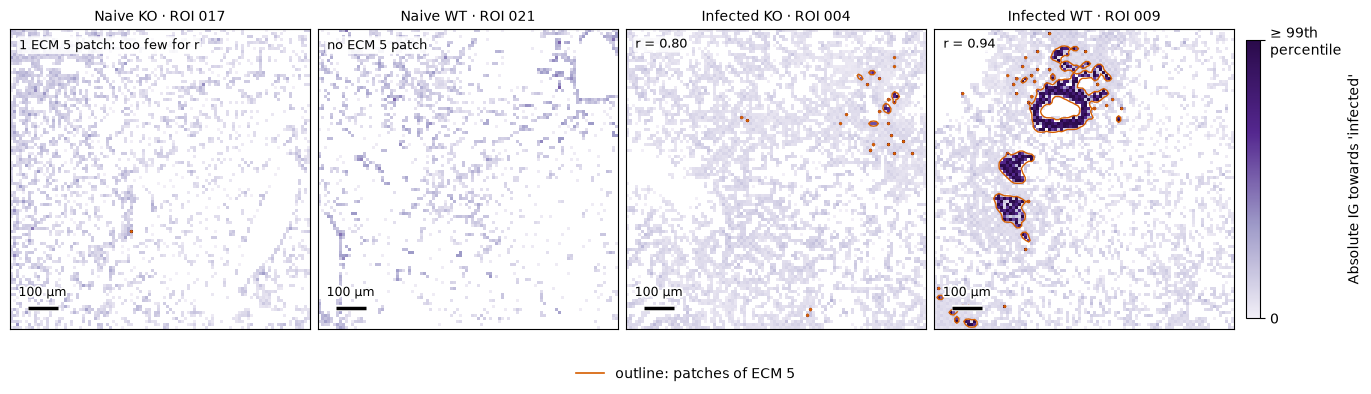

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(13.6, 3.9), layout="constrained")
for ax, (group, roi) in zip(axes, SHOWN_ROIS.items()):
    roi_patches = patches[patches.roi == roi]
    mt.pl.patch_map(roi_patches, "abs_ig_scaled", patch_size=PATCH, shape=(GRID, GRID), cmap=IMPORTANCE_CMAP,
                    vmin=0, vmax=1, ax=ax)
    lh.outline_patches(ax, roi_patches[roi_patches.cluster == INFECTION_CLUSTER], patch_size=PATCH,
                       shape=(GRID, GRID), color=PALETTE[INFECTION_CLUSTER])
    label = lh.correlation_label(shown_localisation.n_cluster_nodes[roi], shown_localisation.pearson_r[roi],
                                 cluster=INFECTION_CLUSTER)
    ax.text(0.03, 0.97, label, transform=ax.transAxes, ha="left", va="top", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    lh.scale_bar(ax, 100 / PATCH, "100 µm")
    ax.set_title(f"{group} · {roi.replace('roi_', 'ROI ')}", fontsize=10)
bar = fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap=IMPORTANCE_CMAP), ax=axes, shrink=0.8, pad=0.01)
bar.set_ticks([0, 1], labels=["0", "≥ 99th\npercentile"])
bar.set_label("Absolute IG towards 'infected'")
fig.legend(handles=[Line2D([], [], color=PALETTE[INFECTION_CLUSTER], linewidth=1.2,
                           label=f"outline: patches of ECM {INFECTION_CLUSTER}")],
           loc="outside lower center", frameon=False)
plt.show()

Panel h shows the same correlation for every cluster and every infected ROI (circles: knockout; squares: wild
type; line: median). ROIs in which the correlation is not defined are left out.

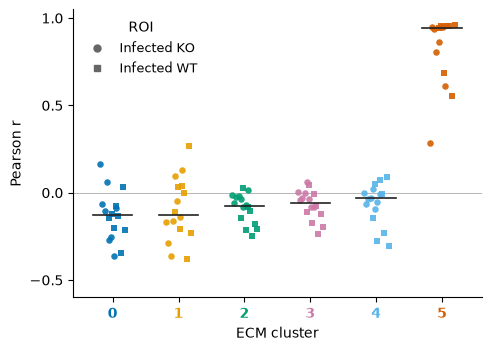

In [32]:
infected_localisation = localisation[localisation.group.str.startswith("Infected")]

fig, ax = plt.subplots(figsize=(4.8, 3.4), layout="constrained")
lh.plot_cluster_correlations(ax, infected_localisation, palette=PALETTE,
                             group_markers={"Infected KO": "o", "Infected WT": "s"})
ax.set_xlabel("ECM cluster")
ax.set_ylabel("Pearson r")
plt.show()

**Comparison with the paper.** The correlations are joined on (ROI, cluster). First the infection-associated
cluster in the two infected ROIs of panel f, then the median over the infected ROIs for every cluster, with
the number of ROIs in which the correlation is defined. The paper's values are the mean of five training
seeds.

In [33]:
keys = ["roi", "cluster"]
both = lh.side_by_side(infected_localisation.set_index(keys).pearson_r, PAPER["localisation"].set_index(keys).pearson_r)

infected_shown = {group: roi for group, roi in SHOWN_ROIS.items() if group.startswith("Infected")}
display(both.xs(INFECTION_CLUSTER, level="cluster").loc[list(infected_shown.values())].round(2))

(both.groupby("cluster").agg(["median", "count"]).rename(columns={"count": "ROIs with r"}, level=1)
 .rename(index="ECM {}".format).round(2))

,this run,paper
roi,,
roi_004,0.80,0.86
roi_009,0.94,0.95


this run              paper            
          median ROIs with r median ROIs with r
cluster                                        
ECM 0      -0.13          16  -0.21          16
ECM 1      -0.13          16  -0.02          16
ECM 2      -0.07          16  -0.09          16
ECM 3      -0.06          16  -0.07          16
ECM 4      -0.03          16  -0.03          16
ECM 5       0.94          15   0.95          14

## 16. Connected regions of the infection-associated cluster (Figure 3i)

`mt.tl.component_summary` with `mode="radius"` joins the patches of one cluster that lie within 40 pixels of
each other and returns the connected groups (subgraphs). Subgraphs of at least five patches are kept. For each
one it reports the number of patches and the mean node degree (2 x edges / patches): a high degree means a
compact, densely filled region.

In [34]:
regions = mt.tl.component_summary(
    cohort, target_cluster=INFECTION_CLUSTER, mode="radius", radius=40.0, min_nodes=5,
    sample_meta=meta, unit_col="mouse", unit_aggregation="pool_components",
)
subgraphs = (regions.components[regions.components.kept.astype(bool)]
             .rename(columns={"sample_id": "roi"}).join(meta[["mouse", "group"]], on="roi")
             [["roi", "mouse", "group", "n_nodes", "n_edges", "mean_degree"]])

# For the maps: every ECM patch, and for the patches of the cluster their region (kept or not) and node degree.
membership = regions.membership.rename(columns={"sample_id": "roi"})[["roi", "node_id", "kept", "degree"]]
region_patches = patches[["roi", "node_id", "x", "y", "cluster"]].merge(
    membership, on=["roi", "node_id"], how="left", validate="one_to_one")
assert (region_patches.kept.notna() == region_patches.cluster.eq(INFECTION_CLUSTER)).all(), \
    "every patch of the cluster, and no other patch, needs a region"

print(f"{len(subgraphs)} subgraphs of at least five patches, in {subgraphs.roi.nunique()} ROIs "
      f"of {subgraphs.mouse.nunique()} mice")

32 subgraphs of at least five patches, in 11 ROIs of 4 mice


The maps show the two infected ROIs of panels d to f: kept subgraphs are coloured by node degree and outlined,
smaller fragments are grey, and the other ECM patches light grey. The plot shows the mean degree of every kept
subgraph in the four infected mice.

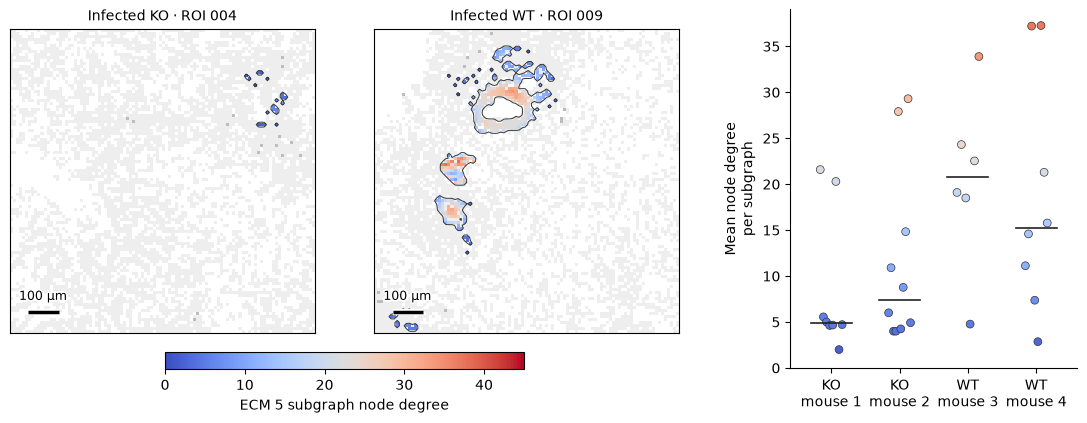

In [35]:
infected_order = [mouse for group in ("Infected KO", "Infected WT") for mouse in sorted(mouse_group.index[mouse_group == group])]

fig = plt.figure(figsize=(11, 4.1), layout="constrained")
left, right = fig.subfigures(1, 2, width_ratios=[2, 1])
axes = left.subplots(1, 2)
for ax, (group, roi) in zip(axes, infected_shown.items()):
    lh.degree_map(ax, region_patches[region_patches.roi == roi], patch_size=PATCH, shape=(GRID, GRID),
                  cmap=DEGREE_CMAP, max_degree=MAX_DEGREE)
    lh.scale_bar(ax, 100 / PATCH, "100 µm")
    ax.set_title(f"{group} · {roi.replace('roi_', 'ROI ')}", fontsize=10)
left.colorbar(ScalarMappable(norm=Normalize(0, MAX_DEGREE), cmap=DEGREE_CMAP), ax=axes, orientation="horizontal",
              shrink=0.5, ticks=[0, 10, 20, 30, 40], label=f"ECM {INFECTION_CLUSTER} subgraph node degree")

ax = right.subplots()
lh.plot_subgraph_degrees(ax, subgraphs, units=infected_order, cmap=DEGREE_CMAP, max_degree=MAX_DEGREE)
ax.set_xticklabels([f"{mouse_group[mouse].split()[-1]}\nmouse {int(mouse.split('_')[-1])}" for mouse in infected_order])
ax.set_ylabel("Mean node degree\nper subgraph")
plt.show()

**Comparison with the paper.** Kept subgraphs per infected mouse: their number, the median number of patches
and the median of the mean node degree.

In [36]:
columns = {"n_components": "subgraphs", "median_nodes": "median patches", "median_mean_degree": "median mean degree"}
paper_regions = PAPER["subgraphs"].groupby("mouse").agg(
    n_components=("n_nodes", "size"), median_nodes=("n_nodes", "median"), median_mean_degree=("mean_degree", "median"))
comparison = lh.side_by_side(regions.per_unit.loc[infected_order, list(columns)], paper_regions).rename(columns=columns)

print(f"Notebook elapsed: {(time.perf_counter() - STARTED) / 60:.1f} min")
comparison.round(1)

Notebook elapsed: 6.0 min


subgraphs  median patches  median mean degree
mouse                                                           
mouse_01 this run          8            13.0                 4.9
         paper             6            12.5                 5.8
mouse_02 this run         10            13.0                 7.4
         paper            10            13.5                 7.7
mouse_03 this run          6           144.5                20.8
         paper             7            61.0                20.2
mouse_04 this run          8            65.5                15.2
         paper             8            68.5                16.3

## 17. Paper and notebook results

The table puts the paper's values beside the values computed in this notebook, panel by panel. The paper's
values are read from its source data (`source_data/fig3.xlsx`).

- **g:** the graph network (GNN) is trained here with seed 0, so the paper's column shows its seed 0.
- **f, h:** the paper's correlations are means of five training seeds.

Every model is trained here from scratch. The encoder uses max pooling, which has no deterministic GPU
implementation in PyTorch (the warning in section 4), so the values differ slightly between GPUs, library
versions and repeated runs of this notebook.

In [37]:
COUNT = "{:,.0f}"
ecm = "ECM {}".format
roi_names = {roi: f"{group}, {roi.replace('roi_', 'ROI ')}" for group, roi in SHOWN_ROIS.items()}
mouse_names = {mouse: f"{mouse_group[mouse]}, mouse {int(mouse.split('_')[-1])}" for mouse in infected_order}
paper_cluster = PAPER["infection_cluster"]

shown_counts = lh.patch_counts(patches, shown_rois, INFECTION_CLUSTER).iloc[:, 1].rename(index=roi_names)
paper_shown = lh.patch_counts(PAPER["shown_patches"], shown_rois, paper_cluster).iloc[:, 1].rename(index=roi_names)
classified = lh.classification_summary(probabilities, infected)
paper_classified = lh.classification_summary(PAPER["probabilities"].loc[infected.index, probabilities.columns], infected)
correlations = both.xs(INFECTION_CLUSTER, level="cluster")
shown_correlations = correlations.loc[list(infected_shown.values())].rename(index=roi_names)
regions_here = regions.per_unit.loc[infected_order].rename(index=mouse_names)
regions_paper = paper_regions.rename(index=mouse_names)

parts = [   # heading, this run, paper, number format
    (f"a: share of ECM {INFECTION_CLUSTER} in each group",
     group_fractions[INFECTION_CLUSTER], PAPER["group_fractions"][paper_cluster], "{:.3f}"),
    (f"a: share of ECM {INFECTION_CLUSTER} in each infected mouse",
     per_mouse.loc[infected_order, INFECTION_CLUSTER].rename(index=mouse_names),
     PAPER["mouse_fractions"].loc[infected_order, paper_cluster].rename(index=mouse_names), "{:.3f}"),
    ("b: ECM signal patches", {"24 ROIs": n_signal}, {"24 ROIs": PAPER["cluster_sizes"].sum()}, COUNT),
    ("b: patches in each cluster",
     pd.Series(sizes).sort_index().rename(ecm), PAPER["cluster_sizes"].rename(ecm), COUNT),
    (f"c: co-occurrence with ECM {INFECTION_CLUSTER}, infected KO minus WT",
     ko_minus_wt[INFECTION_CLUSTER].rename(ecm), PAPER["ko_minus_wt"][paper_cluster].rename(ecm), "{:.2f}"),
    (f"e: patches of ECM {INFECTION_CLUSTER} in the ROIs shown", shown_counts, paper_shown, COUNT),
    (f"g: mice classified correctly (of {len(infected)})", classified.iloc[:, 0], paper_classified.iloc[:, 0], COUNT),
    ("g: ROC AUC", classified["ROC AUC"], paper_classified["ROC AUC"], "{:.3f}"),
    (f"f: correlation of importance with ECM {INFECTION_CLUSTER}",
     shown_correlations["this run"], shown_correlations["paper"], "{:.2f}"),
    (f"h: correlation of importance with ECM {INFECTION_CLUSTER}",
     {"median over the infected ROIs": correlations["this run"].median()},
     {"median over the infected ROIs": correlations["paper"].median()}, "{:.2f}"),
    (f"i: subgraphs of ECM {INFECTION_CLUSTER}", regions_here["n_components"], regions_paper["n_components"], COUNT),
    ("i: median of the mean node degree",
     regions_here["median_mean_degree"], regions_paper["median_mean_degree"], "{:.1f}"),
]
pd.concat({heading: lh.side_by_side(pd.Series(this_run), pd.Series(paper))[["paper", "this run"]].map(form.format)
           for heading, this_run, paper, form in parts}, names=["panel", "result"])

paper  \
panel                                             result                                   
a: share of ECM 5 in each group                   Naive KO                         0.000   
                                                  Naive WT                         0.000   
                                                  Infected KO                      0.040   
                                                  Infected WT                      0.152   
a: share of ECM 5 in each infected mouse          Infected KO, mouse 1             0.033   
                                                  Infected KO, mouse 2             0.048   
                                                  Infected WT, mouse 3             0.095   
                                                  Infected WT, mouse 4             0.210   
b: ECM signal patches                             24 ROIs                        107,740   
b: patches in each cluster                        ECM 0                           32,469   
                                                  ECM 1                           23,232   
                                                  ECM 2                           21,786   
                                                  ECM 3                           11,982   
                                                  ECM 4                           10,036   
                                                  ECM 5                            8,235   
c: co-occurrence with ECM 5, infected KO minus WT ECM 0                             0.79   
                                                  ECM 1                             0.07   
                                                  ECM 2                             4.21   
                                                  ECM 3                             2.29   
                                                  ECM 4                             0.88   
                                                  ECM 5                             1.20   
e: patches of ECM 5 in the ROIs shown             Naive KO, ROI 017                    0   
                                                  Naive WT, ROI 021                    0   
                                                  Infected KO, ROI 004                33   
                                                  Infected WT, ROI 009               408   
g: mice classified correctly (of 8)               GNN, seed 0                          8   
                                                  LR                                   6   
g: ROC AUC                                        GNN, seed 0                      1.000   
                                                  LR                               0.938   
f: correlation of importance with ECM 5           Infected KO, ROI 004              0.86   
                                                  Infected WT, ROI 009              0.95   
h: correlation of importance with ECM 5           median over the infected ROIs     0.95   
i: subgraphs of ECM 5                             Infected KO, mouse 1                 6   
                                                  Infected KO, mouse 2                10   
                                                  Infected WT, mouse 3                 7   
                                                  Infected WT, mouse 4                 8   
i: median of the mean node degree                 Infected KO, mouse 1               5.8   
                                                  Infected KO, mouse 2               7.7   
                                                  Infected WT, mouse 3              20.2   
                                                  Infected WT, mouse 4              16.3   

                                                                                this run  
panel                                             result                                  
a: share of ECM 5 in each group     

[Mantpy](https://github.com/moeghaf/Mantpy) · [dataset](https://doi.org/10.5281/zenodo.21538382) ·
[source data](../source_data/) · [paper figure code](../figures/)